# Regressão — Preço por noite de anúncios do Airbnb em NYC

**Por:** Carolina Amorim e Lara Abduni

**Objetivo:** prever o preço por noite (`price`, em US$) de um anúncio do Airbnb em Nova York a partir de localização,
tipo de acomodação, regras de estadia, disponibilidade e histórico de avaliações.

**Dataset:** [New York City Airbnb Open Data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data)
(Kaggle) — 48.895 anúncios de 2019, 16 colunas.

**Organização (segue o roteiro da APS2):**

| Seção | Item do roteiro |
|---|---|
| 0 | Dados e pipeline de pré-processamento (base para todos os modelos) |
| 1.1 – 1.4 | Seleção e implementação dos modelos: 3 modelos e métrica · hiperparâmetros · mudança no pipeline e seu impacto · curvas de aprendizado |
| 2 | Avaliação do melhor modelo no conjunto de teste |
| 3.1 – 3.4 | Interpretação: coeficientes do linear · importância no ensemble · SHAP global · SHAP em 3 predições |
| 4.1 – 4.3 | Discussão crítica: limitações do modelo · limitações dos dados · operacionalização e manutenção |

As figuras são numeradas (Figura 1 a 14) e cada uma é seguida da sua análise; as decisões citam a figura que as motivou.

In [1]:
# Bibliotecas: manipulação de dados, gráficos, scikit-learn (modelos, validação, métricas) e shap
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import shap

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import loguniform, randint

# Semente fixa para que splits, buscas e amostras sejam reprodutíveis
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 0. Dados e pipeline de pré-processamento

Ordem adotada: carregar → aplicar apenas regras **estruturais** (que não dependem de estatísticas) → **separar treino e
teste** → só então inspecionar, gerar figuras e decidir o pré-processamento, **usando apenas o treino**. Assim nenhuma
estatística do teste influencia as decisões.

In [2]:
# Usa o CSV local se existir; senão baixa o dataset do Kaggle (útil no Colab)
if os.path.exists("AB_NYC_2019.csv"):
    caminho = "AB_NYC_2019.csv"
else:
    import kagglehub
    pasta = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
    caminho = os.path.join(pasta, "AB_NYC_2019.csv")

df = pd.read_csv(caminho)
print("Formato do arquivo:", df.shape)
df.head()

Formato do arquivo: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


### 0.1 Regras estruturais e separação treino/teste

- **`price <= 0`** (11 anúncios): diária zero não é um preço válido para o alvo; é uma regra de validade, não um corte
  baseado em distribuição.
- **Colunas removidas:** `id` e `host_id` (identificadores, não descrevem o imóvel), `name` e `host_name` (texto livre,
  exigiria NLP fora do escopo) e `last_review` (data; a informação de volume e frequência de avaliações permanece em
  `number_of_reviews` e `reviews_per_month`).
- **Split 80/20** com semente fixa, antes de qualquer inspeção.

In [3]:
# Regras estruturais, que não dependem de nenhuma estatística dos dados:
# (i) diária precisa ser positiva; (ii) identificadores, texto livre e data não entram como preditores
n_invalidos = int((df["price"] <= 0).sum())
df = df[df["price"] > 0].copy()
df = df.drop(columns=["id", "host_id", "name", "host_name", "last_review"])

X = df.drop(columns="price")
y = df["price"]

# Split treino/teste ANTES de qualquer estatística, figura ou ajuste: o teste fica intocado até a seção 2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Anúncios com preço <= 0 removidos: {n_invalidos}")
print("Treino:", X_train.shape, " Teste:", X_test.shape)

Anúncios com preço <= 0 removidos: 11
Treino: (39107, 10)  Teste: (9777, 10)


### 0.2 Inspeção do treino e evidências para o pré-processamento

O `describe()` é aplicado **somente ao alvo** (variável numérica) e **somente no treino**. As variáveis categóricas
são inspecionadas por contagem de frequências (Figura 2), não pelo `describe()`.

In [4]:
# A partir daqui, toda inspeção usa SOMENTE o treino
print("Valores ausentes por coluna (treino):")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

# reviews_per_month falta exatamente quando o anúncio não tem reviews?
mesma_posicao = ((X_train["number_of_reviews"] == 0) == X_train["reviews_per_month"].isna()).all()
print("\nAusência de reviews_per_month coincide com number_of_reviews == 0:", mesma_posicao)

# Estatísticas apenas do alvo (numérico), no treino
print("\nprice (treino):")
print(y_train.describe(percentiles=[.5, .9, .99]).round(1).to_string())
print(f"Assimetria: {y_train.skew():.1f}")

Valores ausentes por coluna (treino):
reviews_per_month    8012
dtype: int64

Ausência de reviews_per_month coincide com number_of_reviews == 0: True

price (treino):
count    39107.0
mean       153.2
std        249.2
min         10.0
50%        106.0
90%        269.0
99%        798.8
max      10000.0
Assimetria: 19.7


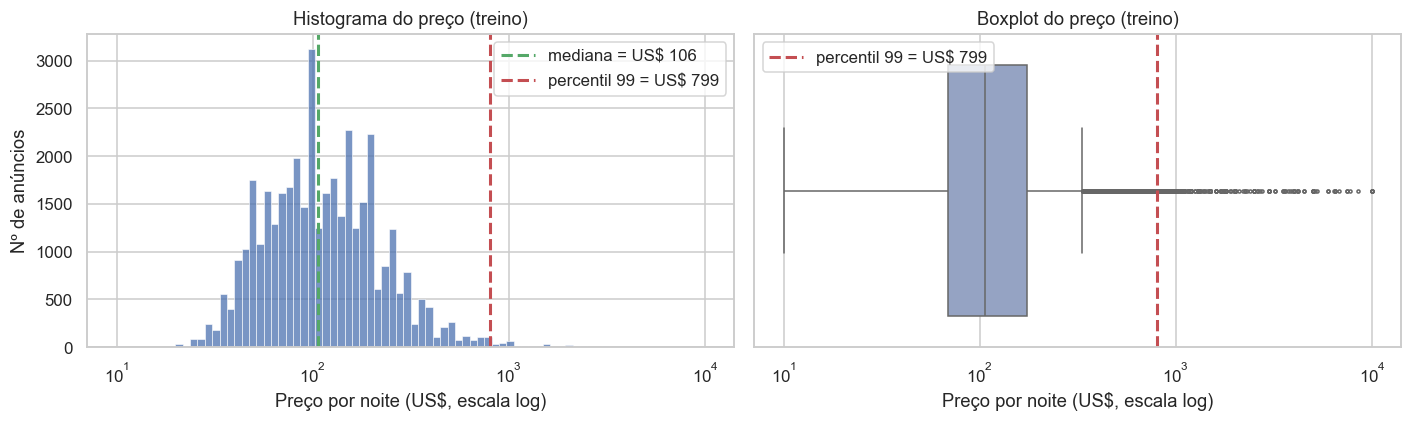

Anúncios acima do p99: 392 (1.0% do treino), preços de US$ 799 a US$ 10000
Participação desses anúncios na soma dos desvios quadráticos em torno da média: 83%


In [5]:
# Figura 1 — distribuição do preço no treino, com mediana e percentil 99 marcados
p50, p99 = y_train.median(), y_train.quantile(0.99)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(y_train, bins=80, log_scale=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(p50, color="#55A868", ls="--", lw=2, label=f"mediana = US$ {p50:.0f}")
ax[0].axvline(p99, color="#C44E52", ls="--", lw=2, label=f"percentil 99 = US$ {p99:.0f}")
ax[0].set_xlabel("Preço por noite (US$, escala log)"); ax[0].set_ylabel("Nº de anúncios")
ax[0].set_title("Histograma do preço (treino)"); ax[0].legend()

sns.boxplot(x=y_train, ax=ax[1], color="#8DA0CB", fliersize=2)
ax[1].set_xscale("log")
ax[1].axvline(p99, color="#C44E52", ls="--", lw=2, label=f"percentil 99 = US$ {p99:.0f}")
ax[1].set_xlabel("Preço por noite (US$, escala log)")
ax[1].set_title("Boxplot do preço (treino)"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

acima = y_train > p99
print(f"Anúncios acima do p99: {acima.sum()} ({acima.mean():.1%} do treino), "
      f"preços de US$ {y_train[acima].min():.0f} a US$ {y_train[acima].max():.0f}")
print(f"Participação desses anúncios na soma dos desvios quadráticos em torno da média: "
      f"{((y_train[acima] - y_train.mean())**2).sum() / ((y_train - y_train.mean())**2).sum():.0%}")

In [6]:
# Decisão tomada a partir da Figura 1: limitar o alvo ao p99 do TREINO e aplicar o mesmo limite ao teste
limite = p99
mask_tr, mask_te = y_train <= limite, y_test <= limite
X_train, y_train = X_train[mask_tr], y_train[mask_tr]
X_test, y_test = X_test[mask_te], y_test[mask_te]

print(f"Limite de preço (p99 do treino): US$ {limite:.2f}")
print(f"Removidos: {(~mask_tr).sum()} do treino e {(~mask_te).sum()} do teste")
print("Treino:", X_train.shape, " Teste:", X_test.shape)

Limite de preço (p99 do treino): US$ 798.76
Removidos: 392 do treino e 100 do teste
Treino: (38715, 10)  Teste: (9677, 10)


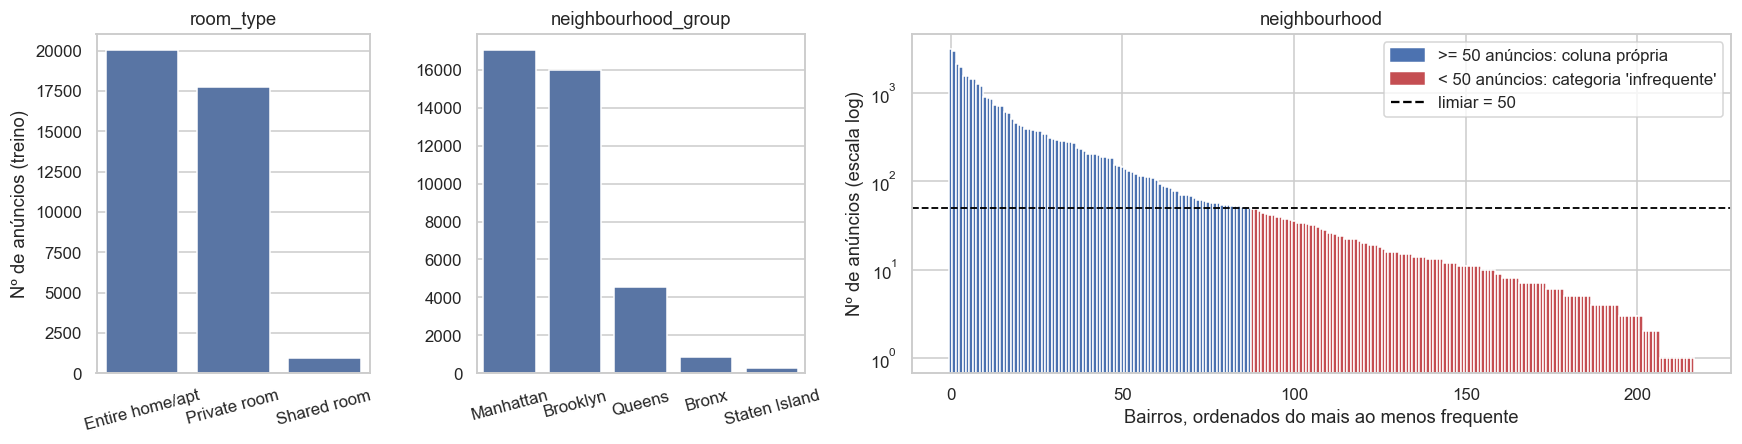

room_type: 3 categorias | neighbourhood_group: 5 | neighbourhood: 217
Bairros com < 50 anúncios: 129 de 217 (4.8% dos anúncios do treino); mediana desses bairros: 11 anúncios


In [7]:
# Figura 2 — frequência das variáveis categóricas no treino (base para o encoding)
cont_room = X_train["room_type"].value_counts()
cont_group = X_train["neighbourhood_group"].value_counts()
cont_bairro = X_train["neighbourhood"].value_counts()
LIMIAR = 50

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.2, 3]})
sns.barplot(x=cont_room.index, y=cont_room.values, ax=ax[0], color="#4C72B0")
ax[0].set_title("room_type"); ax[0].set_xlabel(""); ax[0].set_ylabel("Nº de anúncios (treino)")
ax[0].tick_params(axis="x", rotation=15)

sns.barplot(x=cont_group.index, y=cont_group.values, ax=ax[1], color="#4C72B0")
ax[1].set_title("neighbourhood_group"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
ax[1].tick_params(axis="x", rotation=15)

cores = np.where(cont_bairro.values >= LIMIAR, "#4C72B0", "#C44E52")
ax[2].bar(range(len(cont_bairro)), cont_bairro.values, color=cores, width=1.0)
ax[2].axhline(LIMIAR, color="black", ls="--", lw=1.2)
ax[2].set_yscale("log")
ax[2].set_xlabel("Bairros, ordenados do mais ao menos frequente"); ax[2].set_ylabel("Nº de anúncios (escala log)")
ax[2].set_title("neighbourhood")
ax[2].legend(handles=[Patch(color="#4C72B0", label=f">= {LIMIAR} anúncios: coluna própria"),
                      Patch(color="#C44E52", label=f"< {LIMIAR} anúncios: categoria 'infrequente'"),
                      plt.Line2D([], [], color="black", ls="--", label=f"limiar = {LIMIAR}")])
plt.tight_layout(); plt.show()

raros = cont_bairro[cont_bairro < LIMIAR]
print(f"room_type: {len(cont_room)} categorias | neighbourhood_group: {len(cont_group)} | "
      f"neighbourhood: {len(cont_bairro)}")
print(f"Bairros com < {LIMIAR} anúncios: {len(raros)} de {len(cont_bairro)} "
      f"({raros.sum() / len(X_train):.1%} dos anúncios do treino); mediana desses bairros: {raros.median():.0f} anúncios")

**Análise da Figura 1 (distribuição do preço no treino).** Mesmo em escala log, a distribuição tem cauda longa à direita
(assimetria de 19,7 na escala original): a mediana é US$ 106, o percentil 99 é US$ 799 e o máximo chega a US$ 10.000.
No boxplot, os pontos acima do p99 formam uma cauda rarefeita que se estende por mais de uma ordem de grandeza. Esses
392 anúncios (1,0% do treino) respondem por **83% da soma dos desvios quadráticos** do preço: num modelo avaliado por
RMSE, eles dominariam o ajuste e a métrica.
→ **Decisão:** limitar o alvo ao **p99 do treino (US$ 798,76)** e aplicar o mesmo limite ao teste. O escopo do modelo
passa a ser anúncios de até ~US$ 800/noite; as métricas valem para esse recorte. A mesma figura também motiva a
mudança testada na seção 1.3 (transformação log do alvo).

**Análise da Figura 2 (frequência das categóricas no treino).**
- `room_type` tem 3 categorias, com `Shared room` bem menos frequente (~2% do treino); `neighbourhood_group` tem 5
  distritos, concentrados em Manhattan e Brooklyn, com Bronx e Staten Island pequenos mas ainda com centenas de
  anúncios. Todas são **nominais e com 3 ou mais categorias** → **One-Hot Encoding** (sem ordem artificial). Não há
  variáveis binárias no conjunto, então o OHE não gera colunas redundantes de variáveis 0/1.
- `neighbourhood` tem 217 bairros com frequência muito desigual: o painel em escala log mostra uma cauda de 129 bairros
  com menos de 50 anúncios (mediana de 11), que somam só 4,8% do treino. Um coeficiente estimado com 1 a 10 anúncios
  seria instável.
  → **Decisão:** `OneHotEncoder(min_frequency=50)`: os 88 bairros com 50+ anúncios ganham coluna própria e os demais
  são agrupados numa categoria "infrequente" (a localização fina desses anúncios continua disponível via
  `latitude`/`longitude`).

**Valores ausentes.** No treino, só `reviews_per_month` tem ausentes, e eles coincidem exatamente com
`number_of_reviews == 0` (verificado acima) → **Decisão:** imputar **0** (não há reviews), e não a média. As demais
numéricas não têm ausentes; o imputador pela mediana é apenas preventivo para dados novos.

### 0.3 Pipeline

| Evidência | Decisão no pipeline |
|---|---|
| Ausência de `reviews_per_month` ⇔ zero reviews | `SimpleImputer(constant=0)` nessa coluna |
| Numéricas em escalas muito diferentes (coordenadas, noites, contagens) | `StandardScaler`, para que a penalização L2 do Ridge trate todas na mesma escala |
| Figura 2: categóricas nominais, sem binárias | `OneHotEncoder` |
| Figura 2: 129 bairros com < 50 anúncios | `min_frequency=50` |
| Figura 1: cauda extrema do preço | corte no p99 do treino (feito acima) |

Não usamos **PCA**: há apenas 7 numéricas (sem problema de dimensionalidade), e a seção 3 exige interpretar
coeficientes e importâncias por feature original, o que componentes principais impediriam. Tudo fica dentro de
`Pipeline` + `ColumnTransformer`, ajustado novamente em cada fold da validação cruzada (sem vazamento).

O HistGradientBoosting é criado com `early_stopping=False`. Por padrão (`"auto"`), a parada antecipada liga sozinha
acima de 10 mil linhas, o que faria o `max_iter` tunado ser ignorado e mudaria o regime de ajuste no meio da curva de
aprendizado (seção 1.4).

In [8]:
# Grupos de colunas, cada um com seu tratamento
num_zero = ["reviews_per_month"]                       # ausente = sem reviews -> 0
num_med = ["latitude", "longitude", "minimum_nights", "number_of_reviews",
        "calculated_host_listings_count", "availability_365"]   # imputação preventiva pela mediana
cat_cols = ["neighbourhood_group", "room_type", "neighbourhood"]  # todas nominais com 3+ categorias

def make_preprocessor():
    """Imputação + padronização nas numéricas, one-hot nas categóricas (bairros raros agrupados)."""
    return ColumnTransformer([
        ("num_zero", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0)),
                            ("sc", StandardScaler())]), num_zero),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())]), num_med),
        # limiar definido a partir da Figura 2
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=LIMIAR,
                            sparse_output=False), cat_cols),
    ], verbose_feature_names_out=False)

def make_pipe(model):
    """Pré-processamento + modelo num único Pipeline (ajustado dentro de cada fold, sem vazamento)."""
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

def make_hgb():
    """HistGB sem early stopping: o nº de árvores passa a ser controlado só por max_iter (tunado na seção 1.2)."""
    return HistGradientBoostingRegressor(random_state=RANDOM_STATE, early_stopping=False)

n_feats = make_preprocessor().fit(X_train).get_feature_names_out().shape[0]
print("Número de features depois do pré-processamento:", n_feats)

Número de features depois do pré-processamento: 104


## 1. Seleção e implementação dos modelos

### 1.1 Três modelos e a métrica de desempenho

- **Dummy** (`DummyRegressor`, prevê a média do treino): linha de base; qualquer modelo útil precisa superá-lo.
- **Linear com regularização** (`Ridge`, penalidade L2): simples e interpretável. A regularização controla a magnitude
  dos coeficientes, o que importa porque há muitas colunas one-hot correlacionadas (bairro × distrito × coordenadas).
- **Ensemble de árvores** (`HistGradientBoostingRegressor`): boosting de árvores; captura não-linearidades e interações
  (por exemplo, o efeito da localização depende do tipo de quarto) e é eficiente com ~39 mil linhas.

**Métrica:** **RMSE** (raiz do erro quadrático médio), em US$: mesma unidade do preço e penaliza mais os erros grandes,
que são os mais caros para quem precifica. MAE e R² são reportados como apoio, mas **todas as decisões usam o RMSE**.

**Validação:** `KFold` com 5 folds, embaralhado e com semente fixa, usado em todas as etapas, só no treino.

In [9]:
# Mesma estratégia de validação (KFold 5) e mesma métrica (RMSE) em todas as etapas
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"
resultados = {}

def avalia_cv(nome, modelo):
    """Roda a validação cruzada e guarda RMSE (decisão), MAE e R² (apoio) na tabela de resultados."""
    s = cross_validate(modelo, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring={"rmse": SCORING, "mae": "neg_mean_absolute_error", "r2": "r2"})
    resultados[nome] = {"RMSE (CV)": -s["test_rmse"].mean(), "± RMSE": s["test_rmse"].std(),
                        "MAE (CV)": -s["test_mae"].mean(), "R² (CV)": s["test_r2"].mean()}
    return pd.Series(resultados[nome]).round(3)

# Os 3 modelos com hiperparâmetros padrão
modelos_base = {
    "Dummy (média)": make_pipe(DummyRegressor(strategy="mean")),
    "Ridge (alpha=1, padrão)": make_pipe(Ridge()),
    "HistGB (padrão)": make_pipe(make_hgb()),
}
for nome, m in modelos_base.items():
    avalia_cv(nome, m)
pd.DataFrame(resultados).T.round(2)

,RMSE (CV),± RMSE,MAE (CV),R² (CV)
Dummy (média),103.12,2.43,73.18,-0.0
"Ridge (alpha=1, padrão)",79.66,2.15,49.83,0.4
HistGB (padrão),72.82,1.77,44.42,0.5


**Resultado dos modelos padrão:** o HistGB (RMSE US$ 72,8) supera o Ridge (US$ 79,7), e ambos superam o Dummy
(US$ 103,1). O Ridge já reduz o erro em ~23%, o que mostra sinal linear relevante (tipo de quarto e bairro); o ganho
extra do ensemble indica não-linearidades e interações que o modelo linear não representa.

### 1.2 Seleção de hiperparâmetros

- **Ridge → `GridSearchCV`**: há um único hiperparâmetro relevante (`alpha`), então uma grade em escala log
  (10⁻⁴ a 10⁴, 17 valores) cobre bem o espaço.
- **HistGradientBoosting → `RandomizedSearchCV`** (15 candidatos): cinco hiperparâmetros que interagem (taxa de
  aprendizado, nº de árvores, folhas por árvore, mínimo por folha, L2); a busca aleatória explora esse espaço com muito
  menos ajustes que uma grade completa.

Mesma métrica (RMSE) e mesma validação (KFold 5) da seção 1.1.

Melhor alpha: 1 | RMSE (CV): 79.66


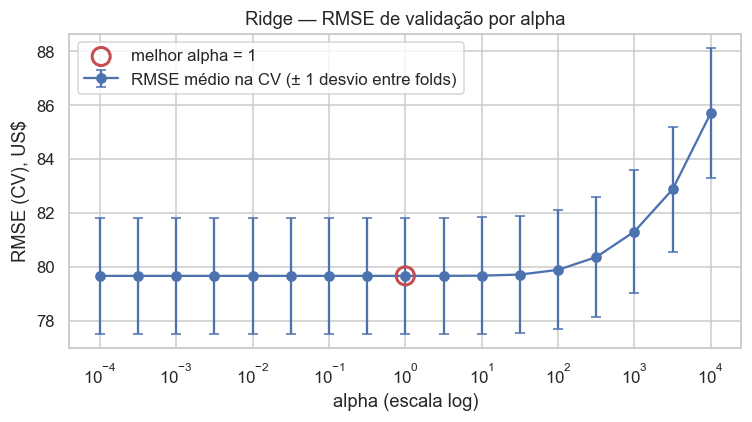

alpha  0.000100      0.000316      0.001000      0.003162      0.010000      0.031623      0.100000      0.316228      1.000000      3.162278      10.000000     31.622777     100.000000    316.227766    1000.000000   3162.277660   10000.000000
rmse          79.66         79.66         79.66         79.66         79.66         79.66         79.66         79.66         79.66         79.66         79.67         79.71         79.89         80.36         81.31         82.88         85.72


In [10]:
# Ridge: grade em escala log, larga o bastante para o mínimo não cair na borda
ALPHAS = np.logspace(-4, 4, 17)
grid_ridge = GridSearchCV(make_pipe(Ridge()), {"model__alpha": ALPHAS},
                          cv=cv, scoring=SCORING, n_jobs=-1)
grid_ridge.fit(X_train, y_train)
melhor_alpha = grid_ridge.best_params_["model__alpha"]
print(f"Melhor alpha: {melhor_alpha:g} | RMSE (CV): {-grid_ridge.best_score_:.2f}")

# Figura 3 — curva de validação: RMSE médio (± desvio entre folds) para cada alpha testado
res = pd.DataFrame(grid_ridge.cv_results_)
a = res["param_model__alpha"].astype(float)
plt.figure(figsize=(7, 4))
plt.errorbar(a, -res["mean_test_score"], yerr=res["std_test_score"], marker="o", capsize=3,
             label="RMSE médio na CV (± 1 desvio entre folds)")
plt.scatter([melhor_alpha], [-grid_ridge.best_score_], s=140, facecolors="none", edgecolors="#C44E52",
            linewidths=2, zorder=3, label=f"melhor alpha = {melhor_alpha:g}")
plt.xscale("log")
plt.xlabel("alpha (escala log)"); plt.ylabel("RMSE (CV), US$"); plt.title("Ridge — RMSE de validação por alpha")
plt.legend(); plt.tight_layout(); plt.show()
print(res.assign(alpha=a, rmse=-res["mean_test_score"])[["alpha", "rmse"]]
      .set_index("alpha").T.round(2).to_string())

In [11]:
# HistGB: busca aleatória sobre os hiperparâmetros que controlam complexidade e regularização
param_hgb = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_iter": randint(150, 600),
    "model__max_leaf_nodes": randint(15, 80),
    "model__min_samples_leaf": randint(10, 100),
    "model__l2_regularization": loguniform(1e-3, 10),
}
rs_hgb = RandomizedSearchCV(make_pipe(make_hgb()), param_hgb, n_iter=15, cv=cv, scoring=SCORING,
                            n_jobs=-1, random_state=RANDOM_STATE)
rs_hgb.fit(X_train, y_train)
print("Melhores hiperparâmetros:")
for k, v in rs_hgb.best_params_.items():
    print(f"  {k}: {v:.4g}")
print(f"RMSE (CV): {-rs_hgb.best_score_:.2f}")

Melhores hiperparâmetros:
  model__l2_regularization: 0.8111
  model__learning_rate: 0.04843
  model__max_iter: 364
  model__max_leaf_nodes: 76
  model__min_samples_leaf: 49
RMSE (CV): 72.47


In [12]:
# Reavalia os modelos tunados com a mesma função, para comparar lado a lado com os padrões
avalia_cv("Ridge (tunado)", grid_ridge.best_estimator_)
avalia_cv("HistGB (tunado)", rs_hgb.best_estimator_)
pd.DataFrame(resultados).T.round(2)

,RMSE (CV),± RMSE,MAE (CV),R² (CV)
Dummy (média),103.12,2.43,73.18,-0.00
"Ridge (alpha=1, padrão)",79.66,2.15,49.83,0.40
HistGB (padrão),72.82,1.77,44.42,0.50
Ridge (tunado),79.66,2.15,49.83,0.40
HistGB (tunado),72.47,1.82,44.09,0.51


**Análise da Figura 3 (curva de validação do Ridge).** O RMSE é praticamente constante (US$ 79,66) de `alpha = 10⁻⁴`
até `alpha ≈ 10` e só piora com penalização forte (US$ 85,7 em 10⁴), quando os coeficientes são encolhidos demais. As
barras de erro (± 1 desvio entre folds, ~US$ 2) são muito maiores que as diferenças dentro do platô. O `alpha = 1`
escolhido está no platô, não na borda da grade. Interpretação: com ~39 mil linhas para 104 colunas, o modelo não sofre de
variância, e a regularização não melhora a generalização; ela só estabiliza os coeficientes de colunas correlacionadas.

**HistGB:** o ajuste reduziu o RMSE de US$ 72,82 para US$ 72,47 (–US$ 0,35). O ganho é real, mas pequeno frente ao desvio
entre folds (~US$ 1,8). A configuração escolhida usa árvores maiores (76 folhas), taxa de aprendizado menor (0,048) e
mais iterações (364) do que o padrão.

**Conclusão parcial:** o **HistGB tunado** é o melhor modelo até aqui (RMSE US$ 72,47, –29,7% em relação ao Dummy). O
tuning trouxe pouco ganho nos dois modelos, o que indica que o limite está mais nas features disponíveis do que nos
hiperparâmetros.

### 1.3 Mudança no pipeline: transformação logarítmica do alvo

**Proposta.** A Figura 1 mostrou que o preço é fortemente assimétrico à direita mesmo após o corte no p99. Além disso,
os efeitos tendem a ser multiplicativos: ser um imóvel inteiro em Manhattan encarece *em proporção*, não num valor fixo.
Modelar `log(1 + price)` deixa o alvo mais simétrico e reduz o peso dos anúncios caros no ajuste.

**Implementação.** `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)` envolvendo o pipeline inteiro. O
modelo treina em escala log, mas as previsões voltam para US$ antes do cálculo da métrica. Assim, o RMSE continua em
dólares e é diretamente comparável com a seção 1.2. **Refazemos a seleção de hiperparâmetros** dos dois modelos com o
mesmo espaço de busca, o mesmo orçamento, a mesma métrica e os mesmos folds.

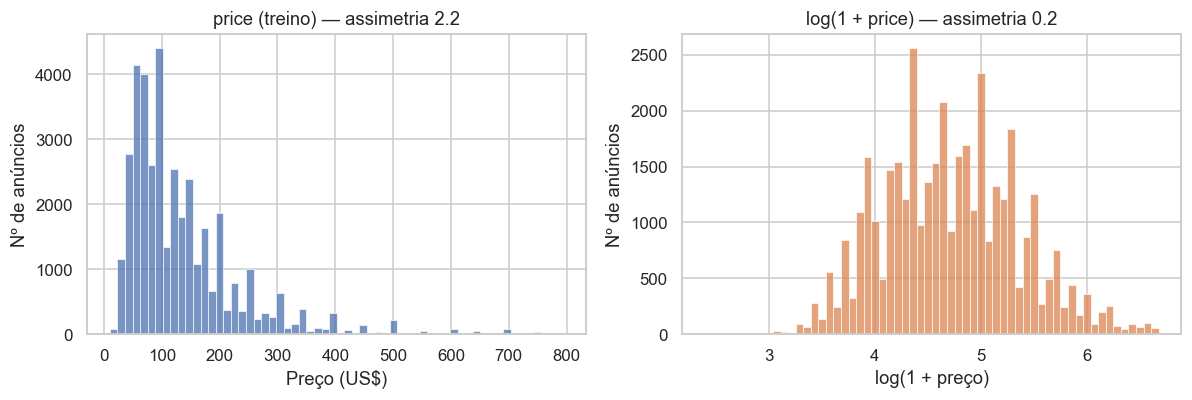

In [13]:
# Figura 4 — distribuição do alvo de treino antes e depois de log(1 + price)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(y_train, bins=60, ax=ax[0], color="#4C72B0")
ax[0].set_title(f"price (treino) — assimetria {y_train.skew():.1f}")
ax[0].set_xlabel("Preço (US$)"); ax[0].set_ylabel("Nº de anúncios")
sns.histplot(np.log1p(y_train), bins=60, ax=ax[1], color="#DD8452")
ax[1].set_title(f"log(1 + price) — assimetria {np.log1p(y_train).skew():.1f}")
ax[1].set_xlabel("log(1 + preço)"); ax[1].set_ylabel("Nº de anúncios")
plt.tight_layout(); plt.show()

In [14]:
def log_target(pipe):
    """Treina em log(1 + price) e devolve as previsões em US$ (RMSE continua comparável)."""
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

# Nova seleção de hiperparâmetros do HistGB, mesmo espaço e orçamento (prefixo muda por causa do wrapper)
param_hgb_log = {k.replace("model__", "regressor__model__"): v for k, v in param_hgb.items()}
rs_hgb_log = RandomizedSearchCV(log_target(make_pipe(make_hgb())), param_hgb_log, n_iter=15, cv=cv,
                                scoring=SCORING, n_jobs=-1, random_state=RANDOM_STATE)
rs_hgb_log.fit(X_train, y_train)
print("Melhores hiperparâmetros (log):")
for k, v in rs_hgb_log.best_params_.items():
    print(f"  {k}: {v:.4g}")
print(f"RMSE (CV): {-rs_hgb_log.best_score_:.2f}")

# Também refazemos o Ridge, com a mesma grade de alpha
grid_ridge_log = GridSearchCV(log_target(make_pipe(Ridge())), {"regressor__model__alpha": ALPHAS},
                              cv=cv, scoring=SCORING, n_jobs=-1)
grid_ridge_log.fit(X_train, y_train)
rmse_alpha_log = pd.Series(-grid_ridge_log.cv_results_["mean_test_score"], index=ALPHAS)
print(f"\nRidge (log) — melhor alpha: {grid_ridge_log.best_params_['regressor__model__alpha']:g}, "
      f"RMSE (CV): {-grid_ridge_log.best_score_:.2f}")
print(f"Variação do RMSE para alpha entre 1e-4 e 10: US$ {rmse_alpha_log[:11].max() - rmse_alpha_log[:11].min():.2f}")

Melhores hiperparâmetros (log):
  regressor__model__l2_regularization: 2.34
  regressor__model__learning_rate: 0.06761
  regressor__model__max_iter: 351
  regressor__model__max_leaf_nodes: 76
  regressor__model__min_samples_leaf: 23
RMSE (CV): 73.22



Ridge (log) — melhor alpha: 0.0001, RMSE (CV): 80.54
Variação do RMSE para alpha entre 1e-4 e 10: US$ 0.07


,RMSE (CV),± RMSE,MAE (CV),R² (CV)
Dummy (média),103.12,2.43,73.18,-0.00
"Ridge (alpha=1, padrão)",79.66,2.15,49.83,0.40
HistGB (padrão),72.82,1.77,44.42,0.50
Ridge (tunado),79.66,2.15,49.83,0.40
HistGB (tunado),72.47,1.82,44.09,0.51
"Ridge (tunado, log)",80.54,2.39,46.20,0.39
"HistGB (tunado, log)",73.22,2.09,41.84,0.50


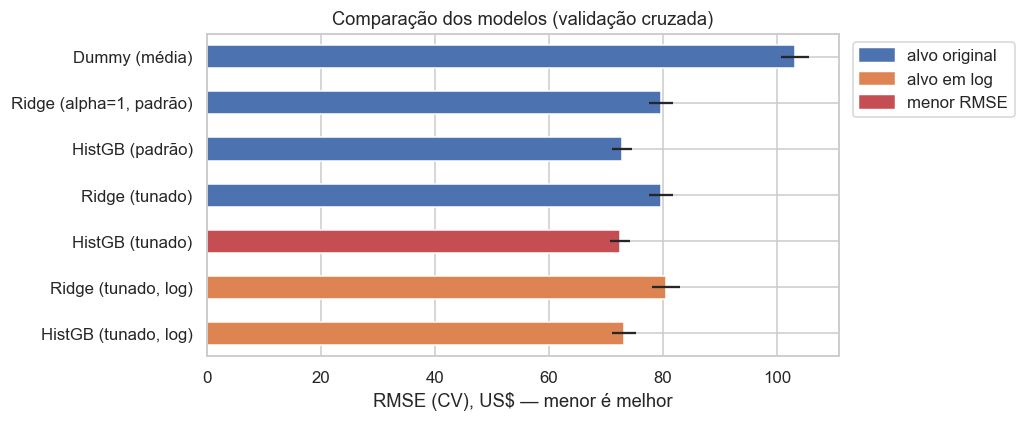

In [15]:
# Tabela final (antes e depois da mudança) + Figura 5: RMSE com desvio entre folds
avalia_cv("Ridge (tunado, log)", grid_ridge_log.best_estimator_)
avalia_cv("HistGB (tunado, log)", rs_hgb_log.best_estimator_)
tabela = pd.DataFrame(resultados).T.round(2)
display(tabela)

melhor_cv = tabela["RMSE (CV)"].idxmin()
cores = ["#C44E52" if n == melhor_cv else ("#DD8452" if "log" in n else "#4C72B0") for n in tabela.index]
ax = tabela["RMSE (CV)"].plot.barh(xerr=tabela["± RMSE"], figsize=(9.5, 4), color=cores)
ax.invert_yaxis(); ax.set_xlabel("RMSE (CV), US$ — menor é melhor"); ax.set_title("Comparação dos modelos (validação cruzada)")
ax.legend(handles=[Patch(color="#4C72B0", label="alvo original"), Patch(color="#DD8452", label="alvo em log"),
                   Patch(color="#C44E52", label="menor RMSE")], loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

**Análise da Figura 4 (alvo antes e depois do log).** O log reduz a assimetria do alvo de treino de 2,2 para 0,2:
a cauda longa à direita vira uma distribuição próxima de simétrica. Isso confirma que a transformação faz o que se propunha *no alvo*. Se
ela melhora a *métrica*, a validação cruzada responde.

**Análise da Figura 5 (comparação na CV) e impacto da mudança:**

| | RMSE (CV) | MAE (CV) |
|---|---|---|
| HistGB tunado (original) | **72,47** | 44,09 |
| HistGB tunado (log) | 73,22 | **41,84** |
| Ridge tunado (original) | **79,66** | 49,83 |
| Ridge tunado (log) | 80,54 | **46,20** |

Com o log, o **MAE cai** ~5% (HistGB) e ~7% (Ridge), mas o **RMSE sobe** ~US$ 0,8 a 0,9 nos dois modelos. A explicação está no
que cada versão otimiza: em log, o modelo minimiza o erro quadrático *relativo*, e `expm1` da previsão em log estima algo
próximo da **mediana** condicional do preço, não da **média** (Duan, 1983). Numa distribuição assimétrica à direita, isso
subestima sistematicamente os anúncios caros, justamente onde o erro quadrático pesa mais. O MAE, menos sensível a esses
poucos erros grandes, melhora porque o modelo acerta melhor a massa de anúncios baratos. No Ridge com log, o melhor `alpha`
ficou na borda inferior (10⁻⁴), mas o RMSE varia só US$ 0,07 entre 10⁻⁴ e 10: é o mesmo platô da Figura 3, não uma grade
curta demais.

**Decisão:** como o RMSE é a métrica de decisão, a mudança é **rejeitada** e o melhor modelo continua sendo o **HistGB
tunado com alvo original**. A transformação do alvo precisa estar alinhada com a métrica: se o objetivo fosse MAE ou erro
percentual, o log seria a escolha.

### 1.4 Curvas de aprendizado do melhor modelo

RMSE de treino e de validação (mesmos 5 folds) para 6 tamanhos de treino, de 10% a 100%.

Melhor modelo: HistGB (tunado)


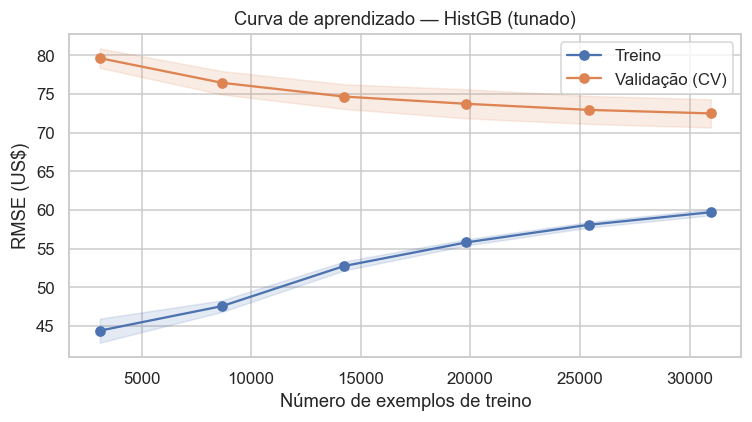

,n_treino,RMSE treino,RMSE validação,gap
0,3097,44.41,79.61,35.20
1,8672,47.58,76.43,28.85
2,14247,52.76,74.65,21.88
3,19822,55.81,73.71,17.90
4,25397,58.08,72.93,14.85
5,30972,59.71,72.47,12.76


In [16]:
# Escolhe o melhor entre os modelos tunados pelo RMSE da CV
candidatos = {"Ridge (tunado)": grid_ridge.best_estimator_,
              "HistGB (tunado)": rs_hgb.best_estimator_,
              "Ridge (tunado, log)": grid_ridge_log.best_estimator_,
              "HistGB (tunado, log)": rs_hgb_log.best_estimator_}
melhor_nome = tabela.loc[list(candidatos), "RMSE (CV)"].idxmin()
melhor = candidatos[melhor_nome]
print("Melhor modelo:", melhor_nome)

# Figura 6 — curva de aprendizado: RMSE de treino e validação (mesmo KFold) para tamanhos crescentes
tamanhos, tr_sc, va_sc = learning_curve(melhor, X_train, y_train, cv=cv, scoring=SCORING,
                                        train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True,
                                        random_state=RANDOM_STATE)
tr, va = -tr_sc, -va_sc
plt.figure(figsize=(7, 4))
for s, nome, c in [(tr, "Treino", "#4C72B0"), (va, "Validação (CV)", "#DD8452")]:
    plt.plot(tamanhos, s.mean(1), marker="o", label=nome, color=c)
    plt.fill_between(tamanhos, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.15, color=c)
plt.xlabel("Número de exemplos de treino"); plt.ylabel("RMSE (US$)")
plt.title(f"Curva de aprendizado — {melhor_nome}"); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"n_treino": tamanhos, "RMSE treino": tr.mean(1), "RMSE validação": va.mean(1),
              "gap": va.mean(1) - tr.mean(1)}).round(2)

**Análise da Figura 6.**
- Com ~3 mil exemplos, o erro de treino (US$ 44) é muito menor que o de validação (US$ 80), um gap de US$ 35: com
  árvores de 76 folhas e 364 iterações, o modelo memoriza boa parte de uma amostra pequena (alta variância).
- À medida que os dados aumentam, o erro de treino **sobe** (fica mais difícil decorar) e o de validação **cai**. O gap
  encolhe continuamente até **US$ 12,8** com ~31 mil exemplos.
- A curva de validação ainda desce no final (US$ 73,7 → 72,9 → 72,5 nos três últimos pontos), mas cada vez menos.
  **Mais dados do mesmo tipo trariam ganho pequeno**, e o gap remanescente mostra que ainda há alguma variância (o modelo
  se ajusta ao treino mais do que generaliza).
- As duas curvas convergem para um patamar alto (~US$ 60–72), o que indica um componente de **viés** importante. Para
  uma melhora relevante, seria preciso informação nova sobre o imóvel, não só mais linhas.

## 2. Avaliação do melhor modelo no conjunto de teste

O HistGB tunado (já reajustado em todo o treino pelo `RandomizedSearchCV`) é avaliado **uma única vez** no teste, que
não participou de nenhuma decisão anterior. O teste segue o mesmo recorte de preço definido no treino (≤ US$ 798,76).

In [17]:
# Avaliação única no teste; o Dummy (média do treino) serve de referência
y_pred = melhor.predict(X_test)
res_test = y_test - y_pred
metricas_teste = pd.Series({
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "MAE": mean_absolute_error(y_test, y_pred),
    "R²": r2_score(y_test, y_pred),
    "RMSE do Dummy (teste)": np.sqrt(mean_squared_error(y_test, np.full_like(y_test, y_train.mean(), dtype=float))),
}).round(2)
metricas_teste

RMSE                      72.67
MAE                       44.31
R²                         0.50
RMSE do Dummy (teste)    102.50
dtype: float64

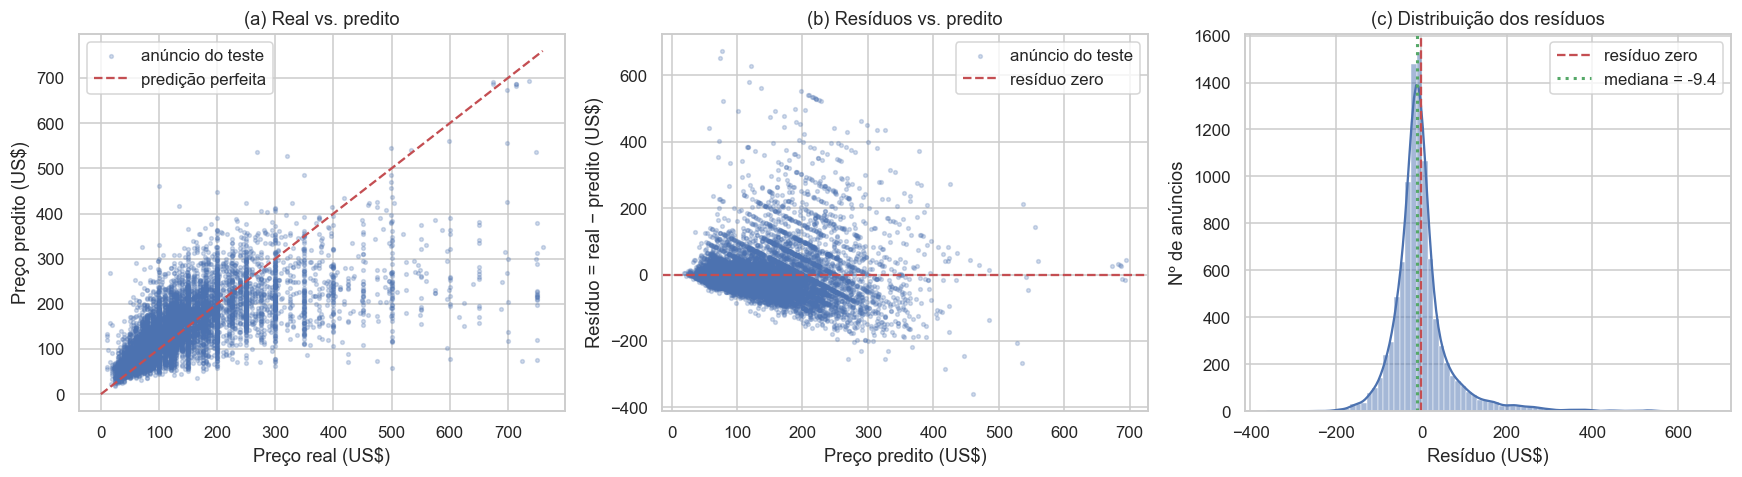

Média dos resíduos: 0.12 | Mediana: -9.37 | Assimetria: 2.47
Resíduos com |erro| > US$100: 9.9% dos anúncios


In [18]:
# Figura 7 — os três diagnósticos de regressão exigidos
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Real vs. predito: quanto mais próximo da diagonal, melhor
ax[0].scatter(y_test, y_pred, s=6, alpha=0.25, label="anúncio do teste")
lim = [0, y_test.max()]
ax[0].plot(lim, lim, "r--", lw=1.5, label="predição perfeita")
ax[0].set_xlabel("Preço real (US$)"); ax[0].set_ylabel("Preço predito (US$)")
ax[0].set_title("(a) Real vs. predito"); ax[0].legend()

# (b) Resíduos vs. predito: procura padrões (viés, heterocedasticidade)
ax[1].scatter(y_pred, res_test, s=6, alpha=0.25, label="anúncio do teste")
ax[1].axhline(0, color="r", ls="--", lw=1.5, label="resíduo zero")
ax[1].set_xlabel("Preço predito (US$)"); ax[1].set_ylabel("Resíduo = real − predito (US$)")
ax[1].set_title("(b) Resíduos vs. predito"); ax[1].legend()

# (c) Distribuição dos resíduos: centro e assimetria do erro
sns.histplot(res_test, bins=80, kde=True, ax=ax[2])
ax[2].axvline(0, color="r", ls="--", lw=1.5, label="resíduo zero")
ax[2].axvline(res_test.median(), color="#55A868", ls=":", lw=2, label=f"mediana = {res_test.median():.1f}")
ax[2].set_xlabel("Resíduo (US$)"); ax[2].set_ylabel("Nº de anúncios")
ax[2].set_title("(c) Distribuição dos resíduos"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"Média dos resíduos: {res_test.mean():.2f} | Mediana: {res_test.median():.2f} | "
      f"Assimetria: {res_test.skew():.2f}")
print(f"Resíduos com |erro| > US$100: {(res_test.abs() > 100).mean():.1%} dos anúncios")

In [19]:
# Erro por faixa de preço real — detalha onde o modelo erra mais (complementa a Figura 7)
faixas = pd.cut(y_test, [0, 75, 150, 250, 400, limite])
pd.DataFrame({"faixa": faixas, "erro_abs": res_test.abs(), "residuo": res_test}) \
  .groupby("faixa", observed=True).agg(n=("erro_abs", "size"), MAE=("erro_abs", "mean"),
                                       residuo_medio=("residuo", "mean")).round(1)

,n,MAE,residuo_medio
faixa,,,
"(0.0, 75.0]",3082,21.9,-19.1
"(75.0, 150.0]",3692,36.1,-21.5
"(150.0, 250.0]",1940,46.3,5.1
"(250.0, 400.0]",712,100.0,87.5
"(400.0, 798.76]",251,268.0,267.2


**Métricas.** RMSE de **US$ 72,67** no teste, contra US$ 72,47 na CV: a estimativa da validação cruzada se confirmou em
dados nunca vistos. O modelo reduz o RMSE em **29%** em relação ao Dummy (US$ 102,50) e explica ~50% da variância do
preço (R² = 0,50). O MAE de US$ 44 indica o erro "típico" de um anúncio.

**Análise da Figura 7.**
- **(a) Real vs. predito:** até ~US$ 250 os pontos acompanham a diagonal. Acima disso, ficam quase todos **abaixo**
  dela: o modelo raramente prevê mais de US$ 400, mesmo para anúncios de US$ 500 a 800. Ele "comprime" as previsões em
  direção à média. As colunas verticais em US$ 100, 150, 200, 250, 300 e 500 são preços redondos muito comuns.
- **(b) Resíduos vs. predito:** a nuvem não é uniforme em torno de zero. Para previsões baixas, os resíduos são
  pequenos e levemente negativos. Para previsões entre US$ 100 e 300, aparecem resíduos positivos muito grandes (até
  +US$ 600), ou seja, a variância do erro cresce com o preço (heterocedasticidade). As "listras" diagonais descendentes
  vêm dos preços redondos: para um preço real fixo, o resíduo cai linearmente conforme a previsão aumenta.
- **(c) Distribuição dos resíduos:** pico estreito perto de zero, média ≈ US$ 0,1, mas **mediana de –US$ 9,4** e
  assimetria positiva forte (2,5), com cauda longa à direita. Na maioria dos anúncios, o modelo **superestima um pouco**;
  numa minoria, **subestima muito**. 9,9% dos anúncios têm erro absoluto acima de US$ 100.

**Erro por faixa de preço real (tabela acima).** Até US$ 150, o MAE fica entre US$ 22 e 36, com superestimação média de
~US$ 20. Entre US$ 250 e 400, o MAE é de US$ 100, e acima de US$ 400 o resíduo médio é de **+US$ 267** (subestimação
severa). O erro agregado esconde que o modelo é bom para o mercado de massa e fraco para os anúncios caros.

## 3. Interpretação e explicabilidade

### 3.1 Modelo linear — as 3 features com coeficientes de maior magnitude

Usamos o **Ridge tunado com alvo original** (coeficientes em US$). Como as numéricas foram padronizadas, um coeficiente
numérico é a variação do preço para +1 desvio-padrão da variável. Para uma coluna one-hot, é a contribuição de o
anúncio pertencer àquela categoria, mantidas as demais features.

,coeficiente (US$)
neighbourhood_Tribeca,103.0
neighbourhood_NoHo,82.4
room_type_Entire home/apt,67.8
neighbourhood_Midtown,65.4
neighbourhood_Flatiron District,65.2
neighbourhood_Inwood,-63.8
neighbourhood_Washington Heights,-59.6
neighbourhood_Cobble Hill,54.4
neighbourhood_group_Staten Island,-48.4
room_type_Shared room,-47.1


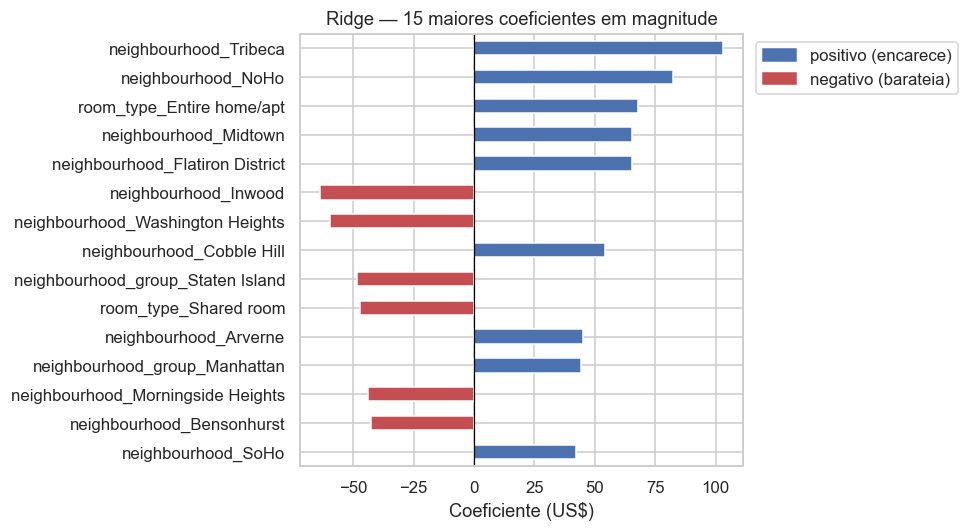

In [20]:
# Coeficientes do Ridge tunado (alvo original, em US$), ordenados por magnitude
ridge_pipe = grid_ridge.best_estimator_
nomes = ridge_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(ridge_pipe.named_steps["model"].coef_, index=nomes)
top_coef = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
display(top_coef.head(10).round(1).to_frame("coeficiente (US$)"))

# Figura 8 — 15 maiores coeficientes; azul = aumenta o preço, vermelho = reduz
top15 = top_coef.head(15).iloc[::-1]
top15.plot.barh(figsize=(9, 5), color=["#C44E52" if v < 0 else "#4C72B0" for v in top15])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coeficiente (US$)"); plt.title("Ridge — 15 maiores coeficientes em magnitude")
plt.legend(handles=[Patch(color="#4C72B0", label="positivo (encarece)"),
                    Patch(color="#C44E52", label="negativo (barateia)")], loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

**Análise da Figura 8.** Os três maiores coeficientes em magnitude são:

1. **`neighbourhood_Tribeca` (+US$ 103):** com as demais features fixas, estar em Tribeca está associado a ~US$ 100 a
   mais na diária. Tribeca é um dos bairros mais caros de Manhattan, então o sinal e a ordem de grandeza são coerentes.
2. **`neighbourhood_NoHo` (+US$ 82):** mesmo padrão: um bairro pequeno e valorizado de Manhattan. O modelo usa
   informação de bairro **além** do distrito e das coordenadas.
3. **`room_type_Entire home/apt` (+US$ 68):** o fator mais forte fora da localização. No mesmo bloco,
   `room_type_Shared room` tem –US$ 47, então o contraste entre imóvel inteiro e quarto compartilhado é de ~US$ 115.

Entre os negativos, Inwood (–US$ 64) e Washington Heights (–US$ 60), no norte de Manhattan, e Staten Island (–US$ 48)
mostram que "estar em Manhattan" não basta: o bairro específico importa. As 15 barras da figura são quase todas
indicadores de bairro ou de tipo de quarto. Nenhuma numérica aparece, o que é coerente com efeitos de localização que não
são lineares nas coordenadas.

**Cuidados:** (i) o OHE mantém todas as categorias (sem categoria de referência omitida), então cada coeficiente é um
componente da parametrização regularizada, e comparações fazem mais sentido *dentro* de um mesmo bloco (como imóvel
inteiro vs. compartilhado); (ii) bairro, distrito e coordenadas carregam informação redundante, e o Ridge distribui o
efeito entre elas; (iii) são associações, não efeitos causais.

### 3.2 Modelo ensemble — as 3 features de maior importância

O `HistGradientBoostingRegressor` não expõe `feature_importances_`, então usamos **importância por permutação** numa amostra
de 3.000 anúncios do teste: cada coluna **original** é embaralhada (5 repetições) e medimos quanto o RMSE piora. Vantagens:
usa a mesma métrica do projeto, mede `room_type` inteiro (não cada coluna one-hot) e não favorece variáveis com muitos
valores distintos, como faz a importância por impureza.

,aumento no RMSE (US$),±
room_type,30.70,0.88
longitude,11.44,0.37
minimum_nights,10.57,0.54
availability_365,10.02,0.55
latitude,7.92,0.46
calculated_host_listings_count,2.68,0.19
reviews_per_month,2.43,0.25
neighbourhood,1.97,0.17
number_of_reviews,1.95,0.17
neighbourhood_group,0.38,0.05


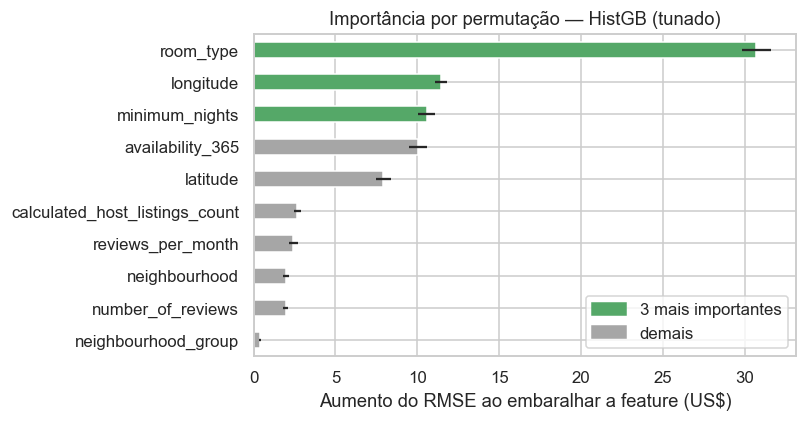

In [21]:
# Importância por permutação no teste (amostra de 3 mil anúncios para reduzir o custo)
amostra = X_test.sample(3000, random_state=RANDOM_STATE)
perm = permutation_importance(melhor, amostra, y_test.loc[amostra.index], scoring=SCORING,
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"aumento no RMSE (US$)": perm.importances_mean, "±": perm.importances_std},
                   index=amostra.columns).sort_values("aumento no RMSE (US$)", ascending=False)
display(imp.round(2))

# Figura 9 — top-3 destacadas
cores = ["#55A868" if f in imp.index[:3] else "#A6A6A6" for f in imp.index[::-1]]
imp["aumento no RMSE (US$)"].iloc[::-1].plot.barh(xerr=imp["±"].iloc[::-1], figsize=(7.5, 4), color=cores)
plt.xlabel("Aumento do RMSE ao embaralhar a feature (US$)")
plt.title(f"Importância por permutação — {melhor_nome}")
plt.legend(handles=[Patch(color="#55A868", label="3 mais importantes"), Patch(color="#A6A6A6", label="demais")],
           loc="lower right")
plt.tight_layout(); plt.show()

**Análise da Figura 9.** As três features mais importantes são:

1. **`room_type` (+US$ 30,7 no RMSE ao embaralhar):** de longe a mais importante, quase 3× a segunda. O tipo de
   acomodação define a faixa de preço antes de qualquer outra coisa, em linha com o Ridge (seção 3.1).
2. **`longitude` (+US$ 11,4):** junto com `latitude` (5ª, +US$ 7,9), representa a localização. Diferente do Ridge, que
   apoia a localização nos indicadores de bairro, o ensemble usa as **coordenadas contínuas**: as árvores recortam
   regiões do mapa diretamente.
3. **`minimum_nights` (+US$ 10,6):** a regra de estadia mínima é informativa para o preço. Ela não aparecia entre os
   maiores coeficientes do Ridge, o que sugere um efeito não linear que as árvores capturam. A direção do efeito aparece
   na seção 3.3.

`availability_365` (+US$ 10,0) fica muito próxima da 3ª posição. As diferenças entre as posições 2 a 4 (~US$ 1) são
pequenas frente aos desvios (~US$ 0,5), então a ordem entre elas não é robusta. `neighbourhood` e `neighbourhood_group`
aparecem com importância baixa porque a informação deles já está em latitude/longitude: ao embaralhar uma feature
correlacionada, o modelo ainda tem a outra, e a permutação subestima as duas.

### 3.3 SHAP no melhor modelo — importância global

`TreeExplainer` (Lundberg; Lee, 2017) aplicado ao HistGB do pipeline, sobre 1.500 anúncios do teste já pré-processados.
Como o melhor modelo usa o alvo original, os **valores SHAP estão em US$**: valor base (previsão média, ~US$ 137) + soma
das contribuições SHAP = preço predito. Como o pré-processamento faz one-hot, cada categoria aparece como uma coluna
(por exemplo `room_type_Entire home/apt`). As numéricas aparecem padronizadas no eixo de cor do beeswarm.

,média |SHAP| (US$)
room_type_Entire home/apt,51.13
longitude,20.31
availability_365,16.22
latitude,12.70
minimum_nights,9.73
reviews_per_month,6.15
number_of_reviews,4.61
calculated_host_listings_count,2.88
neighbourhood_group_Manhattan,2.43
neighbourhood_Midtown,2.28


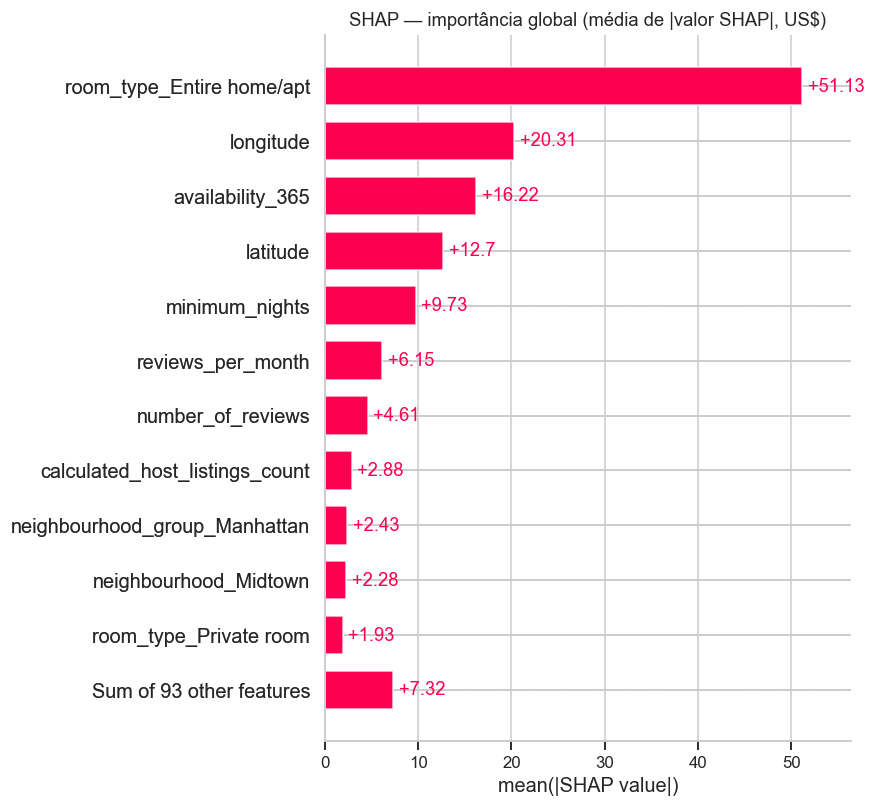

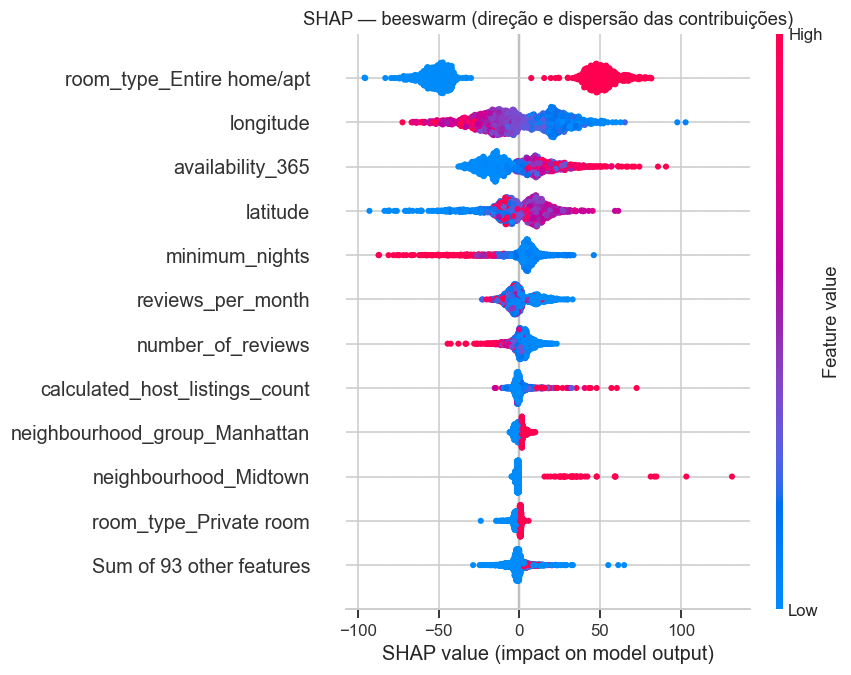

In [22]:
# Separa pré-processamento e HistGB (desembrulhando o TransformedTargetRegressor, se for o caso)
if isinstance(melhor, TransformedTargetRegressor):
    pipe_final, escala_log = melhor.regressor_, True
else:
    pipe_final, escala_log = melhor, False
prep, hgb = pipe_final.named_steps["prep"], pipe_final.named_steps["model"]

# SHAP sobre os dados já transformados (amostra de 1.500 anúncios do teste)
X_shap = amostra.iloc[:1500]
Xt = pd.DataFrame(prep.transform(X_shap), columns=prep.get_feature_names_out(), index=X_shap.index)
explainer = shap.TreeExplainer(hgb)
sv = explainer(Xt)

# Importância global = média do |valor SHAP| por feature
media_abs = pd.Series(np.abs(sv.values).mean(0), index=Xt.columns).sort_values(ascending=False)
display(media_abs.head(10).round(2).to_frame("média |SHAP|" + (" (log)" if escala_log else " (US$)")))

# Figuras 10 e 11 — ranking global e beeswarm
shap.plots.bar(sv, max_display=12, show=False)
plt.title("SHAP — importância global (média de |valor SHAP|, US$)"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP — beeswarm (direção e dispersão das contribuições)"); plt.tight_layout(); plt.show()

**Análise da Figura 10 (média de |SHAP|).** O ranking confirma a permutação: **`room_type_Entire home/apt`
(US$ 51)** domina, seguida de **`longitude` (US$ 20)**, **`availability_365` (US$ 16)**, **`latitude` (US$ 13)** e
**`minimum_nights` (US$ 10)**. A média do valor absoluto mede a magnitude, não a direção.

**Análise da Figura 11 (beeswarm, mostra a direção):**
- **`room_type_Entire home/apt`:** dois blocos separados. Imóvel inteiro (vermelho) soma ~+US$ 50, e os demais (azul)
  ~–US$ 50, uma diferença de ~US$ 100 só pelo tipo de acomodação.
- **`longitude`:** valores altos (vermelho, mais a leste: Queens e o Brooklyn mais distante) puxam o preço para baixo.
  Valores baixos (azul, oeste: Manhattan e o Brooklyn ribeirinho) puxam para cima.
- **`availability_365`:** disponibilidade alta (vermelho) puxa para cima, até +US$ 90; disponibilidade baixa puxa
  levemente para baixo.
- **`latitude`:** latitudes baixas (azul, sul do Brooklyn e Staten Island) reduzem o preço. As faixas intermediárias
  (roxo, Manhattan) aumentam: o efeito não é monotônico, e só um modelo não linear o captura.
- **`minimum_nights`:** estadias mínimas longas (vermelho) produzem contribuições negativas de até –US$ 90, típicas de
  aluguel mensal com diária menor. Valores baixos ficam perto de zero.
- `neighbourhood_Midtown` vale zero para quase todos, mas, quando ativo, soma até +US$ 130. É um efeito raro, mas forte.

As diferenças de ordem em relação à permutação (`availability_365` 3ª no SHAP e 4ª na permutação) são esperadas: o SHAP
mede quanto a feature **move a previsão**, a permutação mede quanto o **erro piora** sem ela.

### 3.4 SHAP — explicação de 3 predições individuais

Escolhemos três anúncios contrastantes da amostra SHAP: o de **menor**, o **mediano** e o de **maior** preço predito.
Cada cascata (Figuras 12 a 14) parte do mesmo valor base (US$ 137,4) e soma as contribuições até a previsão.

=== MENOR PREÇO PREDITO | real: US$ 24 | predito: US$ 25 ===


,neighbourhood_group,neighbourhood,room_type,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
43466,Brooklyn,Bay Ridge,Shared room,10,1,0,12


Valor base: 137.4 US$
Top-5 contribuições SHAP:
  room_type_Entire home/apt              -49.1 US$
  latitude                               -35.4 US$
  longitude                              +14.9 US$
  minimum_nights                          -9.7 US$
  availability_365                        -9.2 US$


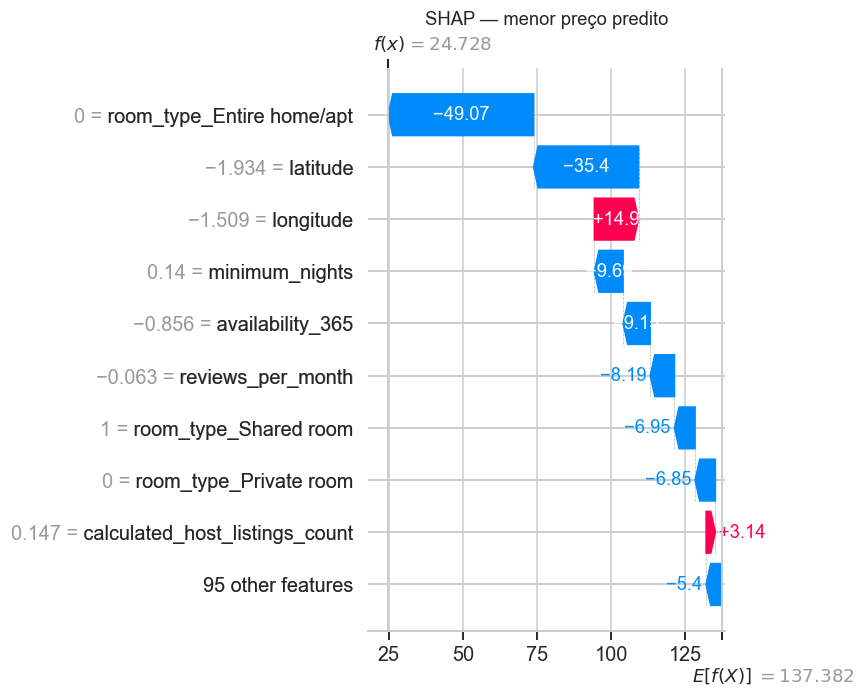

=== PREÇO PREDITO MEDIANO | real: US$ 350 | predito: US$ 123 ===


,neighbourhood_group,neighbourhood,room_type,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
23446,Manhattan,Hell's Kitchen,Private room,2,1,0,1


Valor base: 137.4 US$
Top-5 contribuições SHAP:
  room_type_Entire home/apt              -55.6 US$
  longitude                              +26.3 US$
  latitude                               +21.3 US$
  availability_365                       -18.4 US$
  minimum_nights                          +7.5 US$


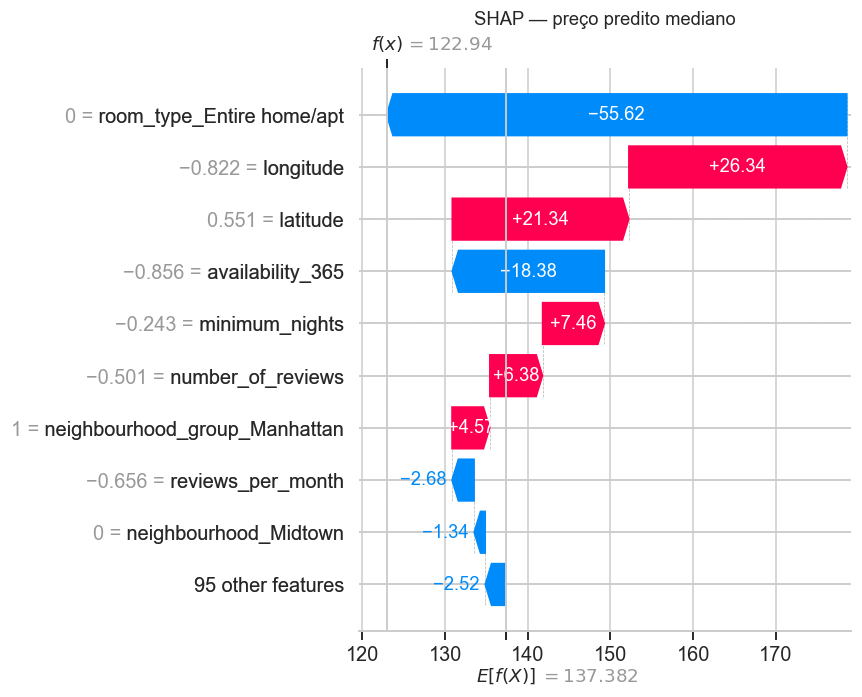

=== MAIOR PREÇO PREDITO | real: US$ 499 | predito: US$ 545 ===


,neighbourhood_group,neighbourhood,room_type,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
19136,Manhattan,Midtown,Private room,3,7,365,12


Valor base: 137.4 US$
Top-5 contribuições SHAP:
  neighbourhood_Midtown                 +131.7 US$
  availability_365                       +90.8 US$
  calculated_host_listings_count         +72.6 US$
  longitude                              +65.3 US$
  room_type_Entire home/apt              -29.9 US$


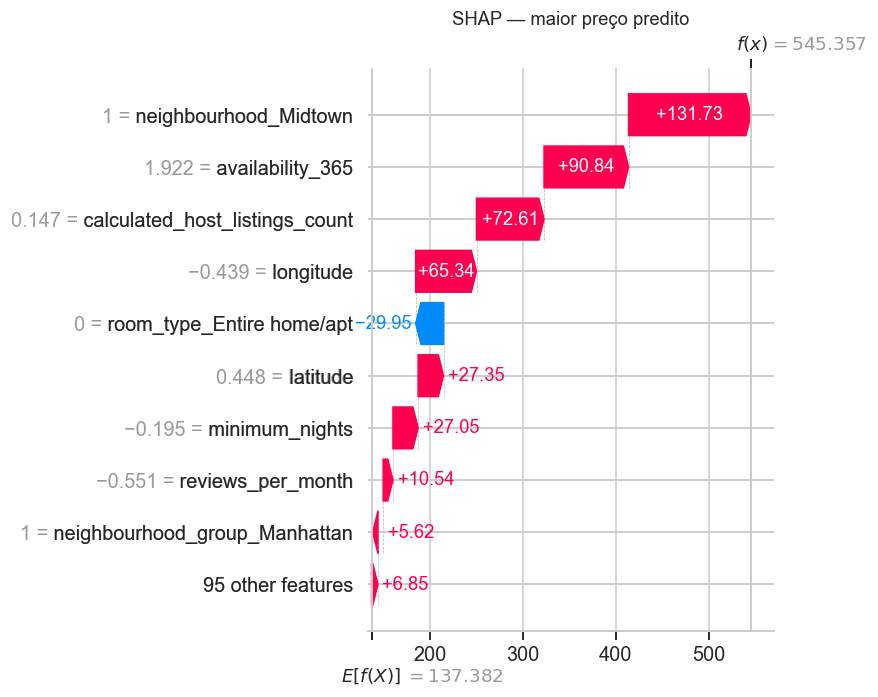

In [23]:
# Três anúncios contrastantes: menor, mediano e maior preço predito na amostra
pred_amostra = pd.Series(melhor.predict(X_shap), index=X_shap.index)
ordem = pred_amostra.sort_values()
escolhidos = {"menor preço predito": ordem.index[0],
              "preço predito mediano": ordem.index[len(ordem) // 2],
              "maior preço predito": ordem.index[-1]}

colunas_ver = ["neighbourhood_group", "neighbourhood", "room_type", "minimum_nights",
               "number_of_reviews", "availability_365", "calculated_host_listings_count"]
for rotulo, idx in escolhidos.items():
    i = X_shap.index.get_loc(idx)
    print(f"=== {rotulo.upper()} | real: US$ {y_test[idx]:.0f} | predito: US$ {pred_amostra[idx]:.0f} ===")
    display(X_shap.loc[[idx], colunas_ver])
    # As 5 features que mais moveram esta previsão (em módulo)
    contrib = pd.Series(sv.values[i], index=Xt.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
    print(f"Valor base: {np.ravel(sv.base_values)[i]:.1f}" + (" (escala log)" if escala_log else " US$"))
    print("Top-5 contribuições SHAP:")
    for f, v in top.items():
        if escala_log:
            print(f"  {f:<35} {v:+.3f}  (x{np.exp(v):.2f})")
        else:
            print(f"  {f:<35} {v:+8.1f} US$")
    # Figuras 12 a 14 — cascata da previsão
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"SHAP — {rotulo}"); plt.tight_layout(); plt.show()

**Figura 12 — menor preço predito: quarto compartilhado em Bay Ridge, Brooklyn (real US$ 24, predito US$ 25).** As duas
maiores contribuições são **não ser imóvel inteiro (–US$ 49)** e a **latitude (–US$ 35)**: Bay Ridge fica no extremo sul do
Brooklyn, a região mais barata na leitura do beeswarm. Estadia mínima de 10 noites (–US$ 10) e disponibilidade zero
(–US$ 9) também reduzem. A longitude soma +US$ 15, porque Bay Ridge fica no lado oeste do Brooklyn. O acerto é quase
exato.

**Figura 13 — preço predito mediano: quarto privado em Hell's Kitchen, Manhattan (real US$ 350, predito US$ 123).** A
localização puxa para cima (**longitude +US$ 26, latitude +US$ 21**, centro-oeste de Manhattan), mas **não ser imóvel
inteiro (–US$ 56)** e a **disponibilidade zero (–US$ 18)** dominam. O modelo **subestima em US$ 227**. Para ele, um quarto
privado com uma única avaliação e sem disponibilidade é um anúncio comum de ~US$ 120, e nada nas features explica uma
diária de US$ 350. É um exemplo concreto da cauda direita dos resíduos da Figura 7(c).

**Figura 14 — maior preço predito: quarto privado em Midtown, Manhattan (real US$ 499, predito US$ 545).** Mesmo sendo
quarto privado (**–US$ 30**), a previsão passa de US$ 500 por uma combinação rara: **Midtown (+US$ 132)**, **disponível
o ano todo (+US$ 91)**, **anfitrião com 12 anúncios (+US$ 73)** e **longitude (+US$ 65)**. O padrão é compatível com
uma operação comercial (por exemplo, quartos de hotel anunciados na plataforma), mas os dados não permitem confirmar isso.
O modelo superestima em US$ 46.

Os três casos mostram o que a importância global não mostra: `room_type`, a feature dominante, pode ser **superada**
num anúncio específico por uma combinação de outras features (caso 3), e um erro grande pode ser explicado pela
**ausência** de informação que diferencie o anúncio (caso 2).

## 4. Discussão crítica

### 4.1 Duas limitações do melhor modelo

1. **Não informa a incerteza da previsão.** O modelo devolve um único valor, mas a seção 2 mostrou que o erro típico
   vai de ~US$ 20 em anúncios baratos a mais de US$ 250 nos caros. Um preço sugerido sem intervalo passa uma confiança
   que o modelo não tem. Alternativas: **regressão quantílica** (Koenker; Bassett, 1978), disponível em
   `HistGradientBoostingRegressor(loss="quantile")`, que estimaria os percentis 10 e 90, ou **predição conformal**
   (Lei et al., 2018), que gera intervalos com cobertura marginal garantida sob a hipótese de permutabilidade, sem supor
   uma distribuição para o erro.
2. **A validação aleatória pode ser otimista para anúncios realmente novos.** Com split e KFold aleatórios, anúncios do
   mesmo prédio ou do mesmo anfitrião (que costuma ter vários anúncios quase iguais) caem ao mesmo tempo em treino e
   validação. O modelo "vê" preços de vizinhos quase idênticos, e o RMSE medido pode ser melhor do que seria para um
   anfitrião novo ou uma região pouco representada. Roberts et al. (2017) mostram que, com dados espacial ou
   hierarquicamente agrupados, a validação aleatória subestima o erro, e Kaufman et al. (2012) tratam esse
   compartilhamento entre treino e teste como uma forma de vazamento. Uma validação com `GroupKFold` por `host_id`, ou
   por blocos espaciais, daria uma estimativa mais honesta.

### 4.2 Duas limitações dos dados

1. **O alvo é o preço pedido, não o preço de mercado.** `price` é o valor que o anfitrião cadastrou no dia da coleta, não
   o valor efetivamente pago. Não sabemos se o anúncio foi reservado por esse preço, nem se havia descontos, taxas de
   limpeza ou variação por data. Muitos anfitriões são ocasionais e precificam de forma pouco consistente; Gibbs et al.
   (2018) encontraram diferenças sistemáticas de preço entre anfitriões profissionais e ocasionais para imóveis
   comparáveis. Parte do erro do modelo é, portanto, ruído do próprio alvo, que nenhuma feature ou modelo consegue
   eliminar.
2. **É um retrato de 2019, de um mercado que mudou.** Os dados são anteriores à pandemia e à *Local Law 18* de NYC
   (Nova York, 2022). Essa lei passou a ser fiscalizada em setembro de 2023, exige o registro do anfitrião e reduziu
   drasticamente a oferta de estadias com menos de 30 noites. A relação entre localização, tipo de quarto, estadia
   mínima e preço provavelmente não é a mesma hoje (*concept drift*; Gama et al., 2014). Há ainda variáveis ambíguas no
   próprio retrato: `availability_365 = 0` pode significar "sempre reservado" ou "anúncio inativo/bloqueado", e o modelo
   não consegue distinguir os dois casos.

### 4.3 Duas ações para operacionalização e manutenção

1. **Empacotar o pipeline completo e validar as entradas.** Serializar pré-processamento + modelo como um único artefato
   (por exemplo `joblib.dump(melhor, "modelo.joblib")`), versionado junto com as versões das bibliotecas, o esquema de
   entrada e o recorte de preço (≤ US$ 799), e servi-lo por uma API simples. Antes de prever, validar tipos, faixas
   plausíveis (coordenadas dentro de NYC, `minimum_nights` > 0) e categorias novas. O
   `OneHotEncoder(handle_unknown="infrequent_if_exist")` já evita que um bairro novo quebre o modelo, mas esses casos
   devem ser registrados. Testes de dados e de esquema estão entre as práticas recomendadas por Breck et al. (2017) e
   reduzem a "dívida técnica" de sistemas de ML descrita por Sculley et al. (2015).
2. **Monitorar *drift* e retreinar com critério.** Acompanhar a distribuição das entradas (proporção por `room_type` e
   distrito, mediana de `minimum_nights`) e, quando houver preços observados, o RMSE/MAE em produção **por faixa de
   preço** (a seção 2 mostrou que o erro agregado esconde a faixa cara). Definir gatilhos (por exemplo, RMSE 15% acima
   do de validação ou mudança forte numa distribuição) e uma rotina de retreino com dados recentes, comparando o
   candidato com o modelo vigente em dados separados (*champion–challenger*) antes de substituí-lo, como nas estratégias
   de adaptação a *concept drift* revisadas por Gama et al. (2014).

## Referências

- BRECK, E.; CAI, S.; NIELSEN, E.; SALIB, M.; SCULLEY, D. The ML test score: a rubric for ML production readiness
  and technical debt reduction. In: *IEEE International Conference on Big Data*, 2017, p. 1123–1132.
- DUAN, N. Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical
  Association*, v. 78, n. 383, p. 605–610, 1983.
- GAMA, J.; ŽLIOBAITĖ, I.; BIFET, A.; PECHENIZKIY, M.; BOUCHACHIA, A. A survey on concept drift adaptation.
  *ACM Computing Surveys*, v. 46, n. 4, art. 44, 2014.
- GIBBS, C.; GUTTENTAG, D.; GRETZEL, U.; MORTON, J.; GOODWILL, A. Pricing in the sharing economy: a hedonic pricing
  model applied to Airbnb listings. *Journal of Travel & Tourism Marketing*, v. 35, n. 1, p. 46–56, 2018.
- KAUFMAN, S.; ROSSET, S.; PERLICH, C.; STITELMAN, O. Leakage in data mining: formulation, detection, and avoidance.
  *ACM Transactions on Knowledge Discovery from Data*, v. 6, n. 4, art. 15, 2012.
- KOENKER, R.; BASSETT, G. Regression quantiles. *Econometrica*, v. 46, n. 1, p. 33–50, 1978.
- LEI, J.; G'SELL, M.; RINALDO, A.; TIBSHIRANI, R. J.; WASSERMAN, L. Distribution-free predictive inference for
  regression. *Journal of the American Statistical Association*, v. 113, n. 523, p. 1094–1111, 2018.
- LUNDBERG, S. M.; LEE, S.-I. A unified approach to interpreting model predictions. In: *Advances in Neural
  Information Processing Systems 30 (NIPS)*, 2017, p. 4765–4774.
- NOVA YORK (Cidade). *Local Law 18 of 2022* — Short-Term Rental Registration Law. Mayor's Office of Special
  Enforcement, 2022.
- ROBERTS, D. R. et al. Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic
  structure. *Ecography*, v. 40, n. 8, p. 913–929, 2017.
- SCULLEY, D. et al. Hidden technical debt in machine learning systems. In: *Advances in Neural Information
  Processing Systems 28 (NeurIPS)*, 2015, p. 2503–2511.